In [1]:
import torch
import math
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from batteryml.pipeline import Pipeline
from batteryml.pipeline import build_dataset
from batteryml.builders import FEATURE_EXTRACTORS, LABEL_ANNOTATORS
from batteryml.feature.base import BaseFeatureExtractor
from batteryml.label.base import BaseLabelAnnotator
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
!rm -rf cache

In [2]:
def plot_predictions_by_battery(y_true, y_pred, cell_ids, is_soh=True, smooth_alpha=None, ncols=2):
    """
    Plot predictions against ground truth, grouping batteries in a grid (two columns by default).
    
    y_true: array or list of ground-truth labels
    y_pred: array or list of predictions
    cell_ids: battery ID for each sample
    smooth_alpha: optional (e.g., 0.05); applies EMA smoothing to each prediction series
    ncols: number of grid columns (two by default, for layouts such as 2x2 or 3x2)
    """
    # Flatten inputs in case they are lists of batches or PyTorch tensors.
    if isinstance(y_true, list):
        y_true = np.concatenate([y.flatten() if isinstance(y, np.ndarray) else y.detach().cpu().numpy().flatten() for y in y_true])
    else:
        y_true = np.array(y_true).flatten()

    if isinstance(y_pred, list):
        y_pred = np.concatenate([p.flatten() if isinstance(p, np.ndarray) else p.detach().cpu().numpy().flatten() for p in y_pred])
    else:
        y_pred = np.array(y_pred).flatten()
        
    cell_ids = np.array(cell_ids).flatten()
    
    unique_cells = np.unique(cell_ids)
    num_cells = len(unique_cells)
    
    if num_cells == 0:
        print("There are no batteries to display.")
        return

    # Calculate the required number of rows automatically.
    nrows = math.ceil(num_cells / ncols)
    
    # Create the overall figure with subplots.
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)
    axes_flat = axes.flatten()  # Flatten the axes array for sequential iteration.
    
    ylabel = 'SOH' if is_soh else 'RUL (cycles)'
    
    for i, cell_id in enumerate(unique_cells):
        ax = axes_flat[i]
        mask = (cell_ids == cell_id)
        y_true_cell = y_true[mask]
        y_pred_cell = y_pred[mask]
        
        # Ground Truth
        ax.plot(y_true_cell, label='Ground truth', color='black', linewidth=2)
        
        # Predictions
        if smooth_alpha is not None:
            ax.plot(y_pred_cell, label='Raw prediction', color='crimson', alpha=0.3, linestyle='--')
            y_pred_smoothed = pd.Series(y_pred_cell).ewm(alpha=smooth_alpha, adjust=False).mean().to_numpy()
            ax.plot(y_pred_smoothed, label=f'EMA (α={smooth_alpha})', color='red', linewidth=1.8)
        else:
            ax.plot(y_pred_cell, label='Prediction', color='crimson', linestyle='--', linewidth=1.5)
            
        ax.set_xlabel('Cycle')
        ax.set_ylabel(ylabel)
        ax.set_title(f'Battery: {cell_id}')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    # Hide unused grid slots when the number of batteries is odd (e.g., 3 batteries in a 2x2 grid).
    for j in range(num_cells, len(axes_flat)):
        axes_flat[j].set_visible(False)
        
    plt.tight_layout()
    plt.show()

# State of health (SOH)

In [20]:
import numpy as np
import torch
import pandas as pd

def create_sliding_window_dataset_soh(
    cells, 
    window_size=5, 
    feature_names=None, 
    flatten=True, 
    mode='relative', 
    as_percentage=False
):
    # Use these three features by default if none are provided.
    if feature_names is None:
        feature_names = [
                    'discharge_duration_s', 
                    'time_CV_s', 
                    'delta_V_drop', 
                    'delta_T', 
                    'R_internal'
        ]
        
    X, y, cell_ids = [], [], []
    
    for cell_idx, cell in enumerate(cells):
        cell_identifier = getattr(cell, 'cell_id', f"Cell_{cell_idx}")
        
        cycle_features = []
        discharge_capacities = []
        
        for cycle in cell.cycle_data:
            # Safely extract the data.
            def get_clean_array(obj, attr_name):
                val = getattr(obj, attr_name, [])
                if val is None:
                    return np.array([])
                if not isinstance(val, (list, tuple, np.ndarray)):
                    val = [val]
                clean_val = [x for x in val if x is not None]
                return np.array(clean_val, dtype=float)
            
            # Extract the raw sensor data.
            v = get_clean_array(cycle, 'voltage_in_V')
            c = get_clean_array(cycle, 'current_in_A')
            t = get_clean_array(cycle, 'time_in_s')
            temp = get_clean_array(cycle, 'temperature_in_C')
            r = get_clean_array(cycle, 'internal_resistance_in_ohm')
            
            # --- CALCULATE ALL INDICATORS ---
            
            # 1. Discharge duration.
            discharge_idx = np.where(c < -0.05)[0] 
            discharge_duration = (t[discharge_idx[-1]] - t[discharge_idx[0]]) if (len(discharge_idx) > 1 and len(t) > 0) else 0.0
                
            # 2. Time in the CV phase.
            cv_idx = np.where((v > 4.15) & (c > 0.01))[0]
            time_cv = (t[cv_idx[-1]] - t[cv_idx[0]]) if (len(cv_idx) > 1 and len(t) > 0) else 0.0
                
            # 3. Initial voltage drop.
            if len(discharge_idx) > 0 and len(v) > 0:
                start_idx = discharge_idx[0]
                v_before = v[start_idx - 1] if start_idx > 0 else v[start_idx]
                v_after = v[min(start_idx + 5, len(v) - 1)]
                delta_v_drop = v_before - v_after
            else:
                delta_v_drop = 0.0
                
            # 4. Temperature rise (for datasets that provide this feature).
            delta_t = (np.max(temp) - np.min(temp)) if len(temp) > 0 else 0.0
                
            # 5. Mean internal resistance (for datasets that provide this feature).
            valid_r = r[r > 0]
            r_mean = np.mean(valid_r) if len(valid_r) > 0 else 0.0

            # --- DYNAMIC DICTIONARY ---
            # Store all calculations in a dictionary keyed by feature name.
            extracted_features_dict = {
                'discharge_duration_s': float(discharge_duration),
                'time_CV_s': float(time_cv),
                'delta_V_drop': float(delta_v_drop),
                'delta_T': float(delta_t),
                'R_internal': float(r_mean)
            }
            
            # Build the cycle vector using only the features listed in feature_names.
            current_cycle_vector = [extracted_features_dict[feat] for feat in feature_names]
            
            cycle_features.append(current_cycle_vector)
            
            # SOH label.
            cap = getattr(cycle, 'discharge_capacity_in_Ah', 0.0)
            if isinstance(cap, (list, np.ndarray, torch.Tensor)):
                cap = float(np.max(cap)) if len(cap) > 0 else 0.0
            else:
                cap = float(cap) if cap is not None else 0.0
            discharge_capacities.append(cap)
                
        total_cycles = len(cycle_features)
        if total_cycles < window_size:
            continue
            
        if mode == 'relative':
            if hasattr(cell, 'nominal_capacity_in_Ah') and cell.nominal_capacity_in_Ah:
                nominal_capacity = float(cell.nominal_capacity_in_Ah)
            else:
                nominal_capacity = discharge_capacities[0] if discharge_capacities[0] > 0 else 1.0

        for i in range(total_cycles - window_size + 1):
            window = cycle_features[i : i + window_size]
            window_array = np.array(window)
            
            # This check uses len(feature_names), so it always matches the input.
            if window_array.shape == (window_size, len(feature_names)):
                if flatten:
                    X.append(window_array.flatten())
                else:
                    X.append(window_array)
                    
                current_cycle_idx = i + window_size - 1
                Qd = discharge_capacities[current_cycle_idx]
                
                if mode == 'relative':
                    soh = Qd / nominal_capacity
                    if as_percentage:
                        soh *= 100.0
                else:
                    soh = Qd 
                    
                y.append(float(soh))
                cell_ids.append(cell_identifier)
            
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), np.array(cell_ids)


In [21]:
# =====================================================================
# 1. THE WORKAROUND: Dummy classes to satisfy the pipeline.
# =====================================================================
if 'DummyFeature' not in FEATURE_EXTRACTORS.class_mapping:
    @FEATURE_EXTRACTORS.register()
    class DummyFeature(BaseFeatureExtractor):
        def process_cell(self, cell): 
            return torch.randn(1)
        # Override __call__ to prevent torch.stack errors.
        def __call__(self, cells):
            return torch.randn(len(cells), 1)

if 'DummyLabel' not in LABEL_ANNOTATORS.class_mapping:
    @LABEL_ANNOTATORS.register()
    class DummyLabel(BaseLabelAnnotator):
        def process_cell(self, cell): 
            return torch.randn(1)
        def __call__(self, cells):
            return torch.randn(len(cells))

# Load the configuration.
pipeline = Pipeline(config_path='configs/baselines/sklearn/rf/calce_rf.yaml', workspace='workspace/calce_rf')

# Temporarily override the in-memory YAML configuration to use the dummy classes.
pipeline.config['feature'] = {'name': 'DummyFeature'}
pipeline.config['label'] = {'name': 'DummyLabel'}

Missing expected config fields: ['feature', 'label', 'feature_transformation', 'label_transformation']
workspace/calce_rf


In [22]:
# =====================================================================
# 2. SAFE DATA EXTRACTION
# =====================================================================
# build_dataset should now run in milliseconds without crashing.
dataset_dummy, raw_data = build_dataset(pipeline.config, device='cpu')

train_cells = raw_data['train_cells']
test_cells = raw_data['test_cells']

Load datasets from cache cache/battery_cache_dfd4a7222254571d1d7f8a59d84bcb89.pkl.


In [23]:
# 4. Generate the final flattened arrays.
window = 5
feature_names = ['charge_capacity_in_Ah', 'current_in_A', 'cycle_number', 'discharge_capacity_in_Ah', 'internal_resistance_in_ohm', 'temperature_in_C', 'time_in_s', 'voltage_in_V']
feature_names = [
    'voltage_in_V', 
    'current_in_A', 
    'temperature_in_C', 
    'time_in_s', 
    'internal_resistance_in_ohm'
]
feature_names = [
    'discharge_duration_s', 
    'time_CV_s', 
    'delta_V_drop'
]
X_train, y_train, train_cell_ids = create_sliding_window_dataset_soh(train_cells, window_size=window, feature_names=feature_names)
X_test, y_test, test_cell_ids = create_sliding_window_dataset_soh(test_cells, window_size=window, feature_names=feature_names)

# 1. Generate column names dynamically in the correct order.
nombres_columnas = []
for i in range(window):
    for feat in feature_names:
        # This generates names such as 'discharge_capacity_in_Ah_0' and 'internal_resistance_in_ohm_0'.
        nombres_columnas.append(f"{feat}_{i}")

X_train_df = pd.DataFrame(X_train, columns=nombres_columnas)
X_test_df = pd.DataFrame(X_test, columns=nombres_columnas)
y_train_df = pd.DataFrame(y_train, columns=['SOH'])
y_test_df = pd.DataFrame(y_test, columns=['SOH'])

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape} | y_test shape: {y_test.shape}")

X_train shape: (9047, 15) | y_train shape: (9047,)
X_test shape: (5199, 15) | y_test shape: (5199,)


## Random Forest

In [24]:
# =====================================================================
# 5. TRAINING WITH SCIKIT-LEARN
# =====================================================================
print("Training the Random Forest...")
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_df, y_train_df.values.ravel())

Training the Random Forest...


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [25]:
# 6. Evaluation
predictions = rf_model.predict(X_test)
rmse = np.sqrt(np.mean((predictions - y_test)**2))
print(f"Test set RMSE (sliding window): {rmse:.2f}")

Test set RMSE (sliding window): 0.06


/home/ander/miniconda3/envs/batteryml/lib/python3.11/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


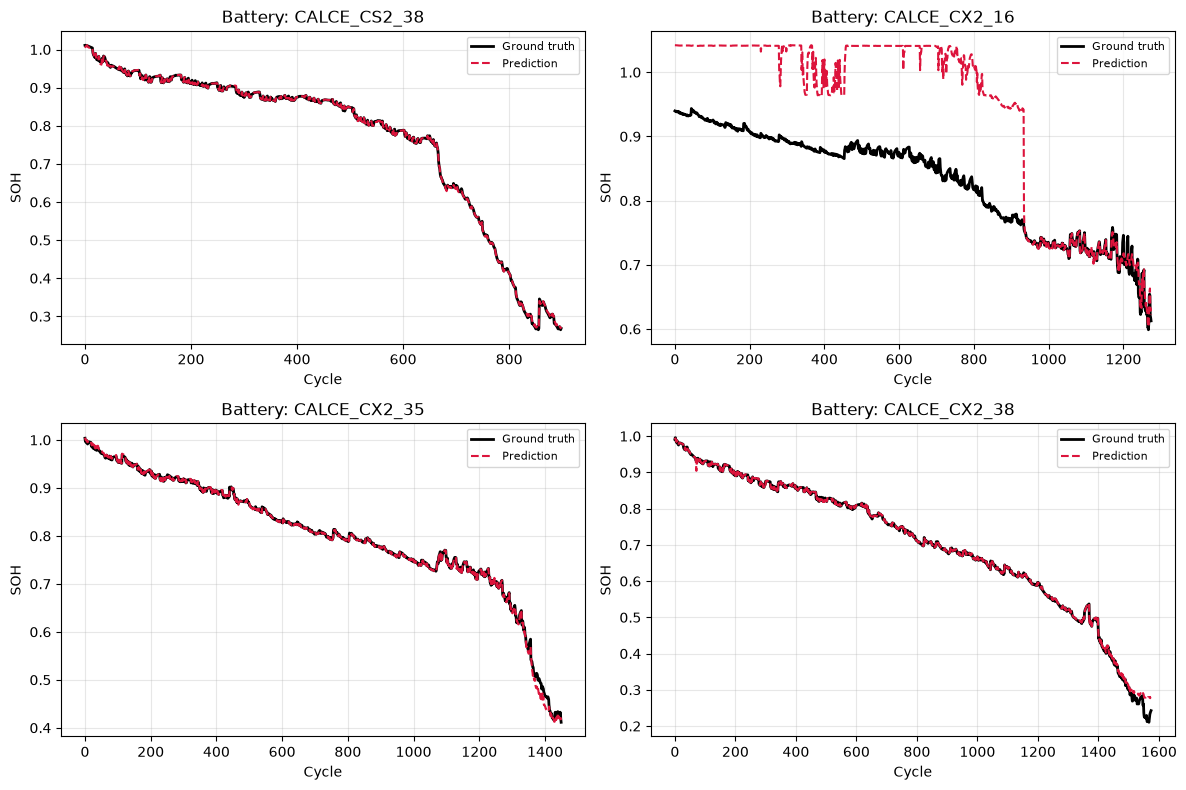

In [26]:
# plot_ground_truth_vs_predictions(predictions, y_test, is_soh=True)
predictions_flat = np.concatenate([p.flatten() for p in predictions])
y_test_flat = np.concatenate([y.flatten() for y in y_test])
plot_predictions_by_battery(y_test_flat, predictions_flat, cell_ids=test_cell_ids, is_soh=True)

## MLP (Sklearn)

In [27]:
window = 5
X_train, y_train, train_cell_ids = create_sliding_window_dataset_soh(train_cells, window_size=window, feature_names=feature_names, flatten=True)
X_test, y_test, test_cell_ids = create_sliding_window_dataset_soh(test_cells, window_size=window, feature_names=feature_names, flatten=True)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((9047, 15), (9047,), (5199, 15), (5199,))

In [28]:
# Scale the data (mean 0, variance 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [29]:
from sklearn.neural_network import MLPRegressor
print("Training the classic MLP...")
mlp_model = MLPRegressor(
    hidden_layer_sizes=(64, 32),  # Two hidden layers with 64 and 32 neurons.
    activation='relu',            # A standard, efficient activation function.
    solver='adam',                # Modern optimizer.
    max_iter=500,                 # Maximum number of training epochs.
    early_stopping=True,          # Stop when improvement stalls to prevent overfitting.
    random_state=42
)

mlp_model.fit(X_train_scaled, y_train)

Training the classic MLP...


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solv

In [30]:
predictions = mlp_model.predict(X_test_scaled)
rmse = np.sqrt(np.mean((predictions - y_test)**2))
print(f"Classic MLP RMSE (sliding window): {rmse:.2f}")

Classic MLP RMSE (sliding window): 0.09


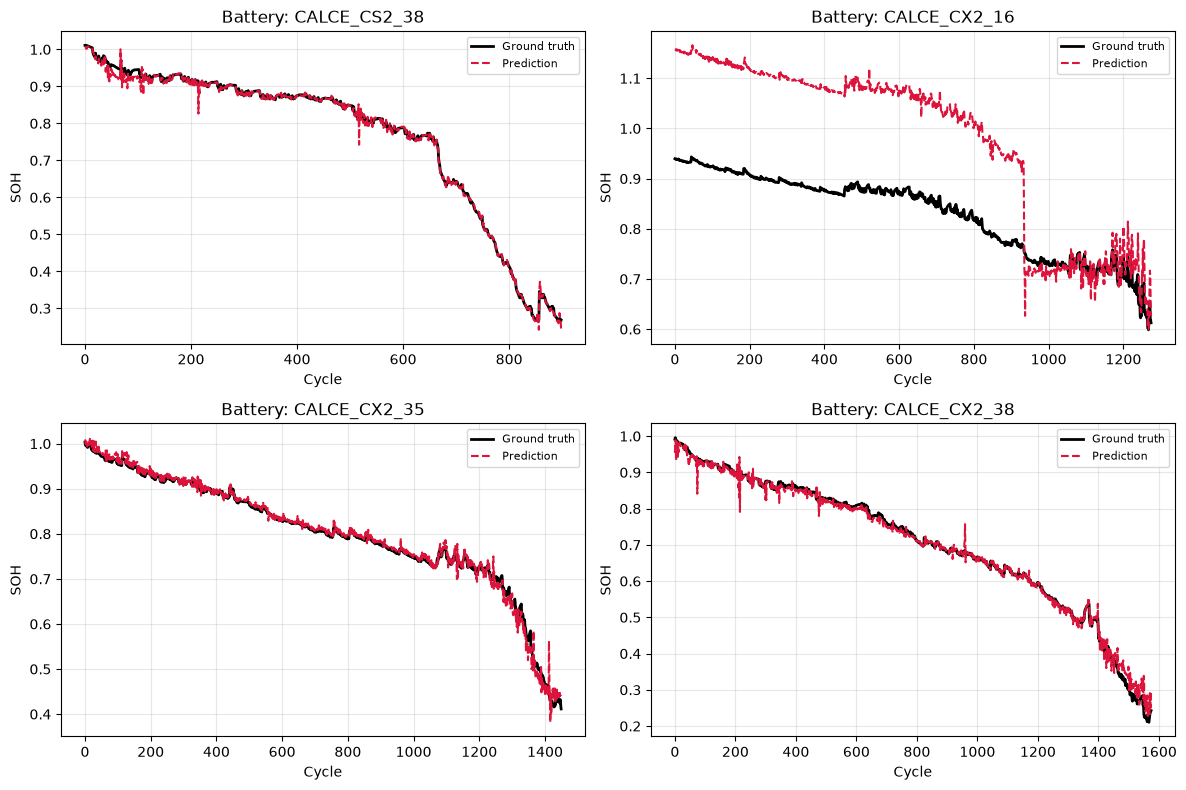

In [31]:
# plot_ground_truth_vs_predictions(predictions, y_test, is_soh=True)
predictions_flat = np.concatenate([p.flatten() for p in predictions])
y_test_flat = np.concatenate([y.flatten() for y in y_test])
plot_predictions_by_battery(y_test_flat, predictions_flat, cell_ids=test_cell_ids, is_soh=True)

## MLP (Pytorch)

In [32]:
import torch
from torch import nn
from torch.utils.data import Dataset, Subset, DataLoader

# For reproducibility
torch.manual_seed(0)

class MyMLP(nn.Module):
# Add input_dim, hidden_dim, and output_dim as arguments.
    def __init__(self, input_dim, hidden_dim=256, output_dim=1, dropout_rate=0.2):
        super(MyMLP, self).__init__()
        
        # Layer 1.
        self.linear1 = nn.Linear(input_dim, hidden_dim)
        torch.nn.init.kaiming_uniform_(self.linear1.weight)
        self.batch1 = nn.LayerNorm(hidden_dim)
        
        # Layer 2.
        self.linear2 = nn.Linear(hidden_dim, hidden_dim//2)
        torch.nn.init.kaiming_uniform_(self.linear2.weight)
        self.batch2 = nn.LayerNorm(hidden_dim//2)
        
        # Layer 3.
        self.linear3 = nn.Linear(hidden_dim//2, hidden_dim//2)
        torch.nn.init.kaiming_uniform_(self.linear3.weight)
        self.batch3 = nn.LayerNorm(hidden_dim//2)

        # Output layer.
        self.linear4 = nn.Linear(hidden_dim//2, output_dim)
        torch.nn.init.kaiming_uniform_(self.linear4.weight)

        self.relu = nn.ReLU()
        self.drop = nn.Dropout(dropout_rate)

    def forward(self, x):
        x = self.linear1(x)
        x = self.batch1(x)
        x = self.relu(x)
        x = self.drop(x)
        
        x = self.linear2(x)
        x = self.batch2(x)
        x = self.relu(x)
        x = self.drop(x)

        x = self.linear3(x)
        x = self.batch3(x)
        x = self.relu(x)

        # For regression, return the raw value without a final activation.
        out = self.linear4(x)
        return out



In [33]:
import torch
import math


def train_loop_soh(dataloader, model, loss_fn, optimizer, device):
    model.train()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    train_loss = 0
    total_squared_error_cycles = 0  # Accumulated squared error in actual cycles.

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # 1. Compute predictions and loss on a [0, 1] scale for stable optimization.
        pred = model(X)
        loss = loss_fn(pred, y)

        # 2. Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Accumulate the normalized batch loss.
        train_loss += loss.item()

        
        # Accumulate the squared error in cycles.
        total_squared_error_cycles += torch.sum((pred - y) ** 2).item()

        if batch % 100 == 0:
            current = batch * len(X)
            # Calculate this batch's RMSE in actual cycles.
            batch_rmse_cycles = math.sqrt(torch.mean((pred - y) ** 2).item())
            print(f"MSE (normalized): {loss.item():>7f} | Batch RMSE: {batch_rmse_cycles:>7.2f} cycles  [{current:>5d}/{size:>5d}]")

    # 4. Calculate the epoch-wide RMSE in actual cycles.
    avg_loss = train_loss / num_batches
    epoch_rmse_cycles = math.sqrt(total_squared_error_cycles / size)
    
    return avg_loss, epoch_rmse_cycles

def test_loop_soh(dataloader, model, loss_fn, device):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss = 0
    total_squared_error = 0
    predictions_list = []

    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            y = y.to(device)
            pred = model(X)
            predictions_list.append(pred)

            test_loss += loss_fn(pred, y).item()

            # Accumulate the squared error in cycles.
            total_squared_error += torch.sum((pred - y) ** 2).item()

    avg_loss = test_loss / num_batches
    test_rmse = math.sqrt(total_squared_error / size)
    
    print(f"Test error: \n RMSE: {test_rmse:>0.2f}, average MSE loss: {avg_loss:>8f} \n")
    return avg_loss, test_rmse, predictions_list

In [56]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

window = 5
# 1. Set aside 15-20% of the cells for validation (development set).
train_cells_split, dev_cells_split = train_test_split(train_cells, test_size=0.20, random_state=42)

# 2. Create separate datasets.
X_train, y_train, train_cell_ids = create_sliding_window_dataset_soh(train_cells_split, window_size=window, feature_names=feature_names)
X_dev, y_dev, dev_cell_ids     = create_sliding_window_dataset_soh(dev_cells_split, window_size=window, feature_names=feature_names)
X_test, y_test, test_cell_ids   = create_sliding_window_dataset_soh(test_cells, window_size=window, feature_names=feature_names)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled   = scaler.transform(X_dev)
X_test_scaled  = scaler.transform(X_test)

# 3. Convert the arrays to PyTorch tensors.
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_dev_tensor   = torch.tensor(X_dev_scaled, dtype=torch.float32)
y_dev_tensor   = torch.tensor(y_dev, dtype=torch.float32).view(-1, 1)

X_test_tensor  = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

# 4. Create TensorDatasets.
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
dev_dataset   = TensorDataset(X_dev_tensor, y_dev_tensor)
test_dataset  = TensorDataset(X_test_tensor, y_test_tensor)

# 5. Create DataLoaders (do not shuffle the development or test sets).
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
dev_dataloader   = DataLoader(dev_dataset, batch_size=64, shuffle=False)
test_dataloader  = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [57]:
X_train_scaled.shape[1]

15

In [58]:
import time
from early_stopping import EarlyStopping

early_stopping = EarlyStopping(patience=50, delta=1e-4, save_path='best_mlp_soh.pt')

learning_rate = 5e-4
batch_size = 64
epochs = 200
weight_decay = 1e-3

# For reproducibility
torch.manual_seed(0)

model = MyMLP(input_dim=X_train_scaled.shape[1], hidden_dim=256*2, output_dim=1, dropout_rate=0.5)
########################
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# print('Using {} device'.format(device))
model = model.to(device)
# print(model)


loss_fn = nn.MSELoss()
# loss_fn = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200, eta_min=0)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=20, min_lr=1e-6
)
########################

stopping_epoch = epochs  # Default to the full number of epochs if early stopping doesn't trigger
train_losses, train_accuracies, dev_losses, dev_accuracies = [], [], [], []
start = time.time()
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loss, train_rmse = train_loop_soh(train_dataloader, model, loss_fn, optimizer, device)
    dev_loss, dev_rmse, _ = test_loop_soh(dev_dataloader, model, loss_fn, device)
    
    print(f"Epoch {t+1}: Train RMSE = {train_rmse:.4f} | Dev RMSE = {dev_rmse:.4f}")
    
    # 3. The scheduler adjusts the learning rate based on dev_loss.
    scheduler.step(dev_loss)
    dev_losses.append(dev_loss)
    dev_accuracies.append(dev_rmse)
    train_losses.append(train_loss)
    train_accuracies.append(train_rmse)
    early_stopping(dev_loss, model, t)
    
    if early_stopping.early_stop:
        print(f"\n[Early stopping] Development performance did not improve for {early_stopping.patience} epochs. Stopping training...")
        stopping_epoch = t + 1
        break

end = time.time()
print("Done!")
print(f'Training time: {end-start}')
early_stopping.restore_best_weights(model)

Epoch 1
-------------------------------
MSE (normalized): 0.693176 | Batch RMSE:    0.83 cycles  [    0/ 7323]
MSE (normalized): 0.069268 | Batch RMSE:    0.26 cycles  [ 6400/ 7323]
Test error: 
 RMSE: 0.17, average MSE loss: 0.030240 

Epoch 1: Train RMSE = 0.3762 | Dev RMSE = 0.1730
Epoch 2
-------------------------------
MSE (normalized): 0.041633 | Batch RMSE:    0.20 cycles  [    0/ 7323]
MSE (normalized): 0.030907 | Batch RMSE:    0.18 cycles  [ 6400/ 7323]
Test error: 
 RMSE: 0.14, average MSE loss: 0.020972 

Epoch 2: Train RMSE = 0.1992 | Dev RMSE = 0.1432
Epoch 3
-------------------------------
MSE (normalized): 0.041543 | Batch RMSE:    0.20 cycles  [    0/ 7323]
MSE (normalized): 0.025862 | Batch RMSE:    0.16 cycles  [ 6400/ 7323]
Test error: 
 RMSE: 0.12, average MSE loss: 0.013947 

Epoch 3: Train RMSE = 0.1582 | Dev RMSE = 0.1160
Epoch 4
-------------------------------
MSE (normalized): 0.020945 | Batch RMSE:    0.14 cycles  [    0/ 7323]
MSE (normalized): 0.023445 | Ba

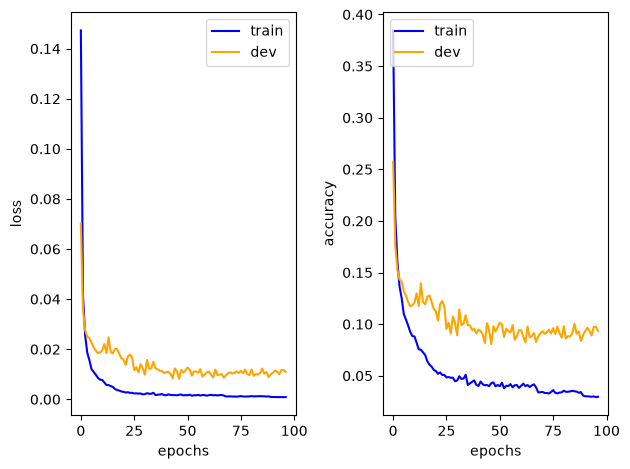

In [54]:
import matplotlib.pyplot as plt

plt.subplot(1, 2, 1)
plt.plot(range(stopping_epoch), train_losses, color='blue', label='train')
plt.plot(range(stopping_epoch), dev_losses, color='orange', label='dev')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend(loc='upper right')

plt.subplot(1, 2, 2)
plt.plot(range(stopping_epoch), train_accuracies, color='blue', label='train')
plt.plot(range(stopping_epoch), dev_accuracies, color='orange', label='dev')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [55]:
model.eval()
test_loss, test_rmse, predictions = test_loop_soh(test_dataloader, model, loss_fn, device)
print(f'test loss: {test_loss}, test_rmse: {test_rmse}')

Test error: 
 RMSE: 0.05, average MSE loss: 0.003097 

test loss: 0.0030967139374286174, test_rmse: 0.05416843593588891


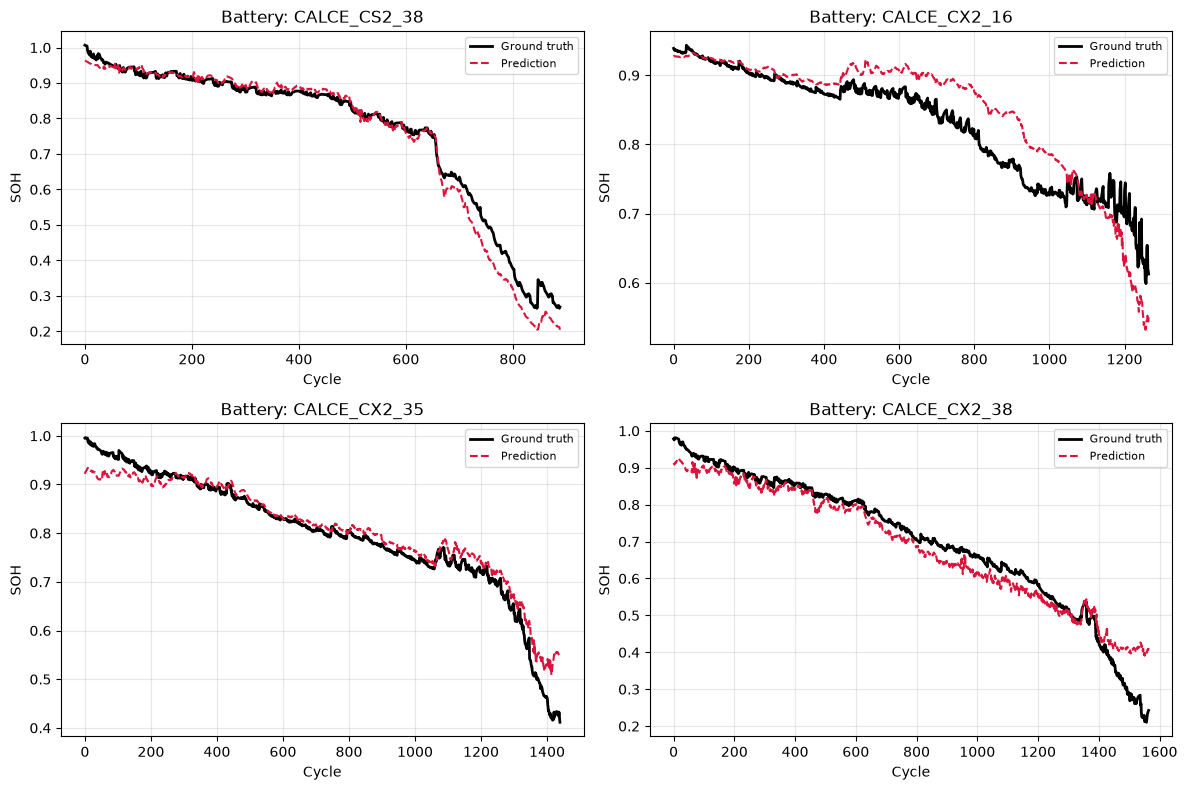

In [52]:
# plot_ground_truth_vs_predictions(predictions, y_test, is_soh=True)
predictions_flat = np.concatenate([p.flatten() for p in predictions])
y_test_flat = np.concatenate([y.flatten() for y in y_test])
plot_predictions_by_battery(y_test_flat, predictions_flat, cell_ids=test_cell_ids, is_soh=True)